# homework 3.3: local minima, convexity, and gradient descent

Aashir Javed | MAT 422

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aaxhirrr/mat-422-fall-2026/blob/AASHIR/hw3-3/HW3.3/HW3_3_optimization.ipynb)

A zero gradient gives us a candidate for a minimum, but it does not finish the job. I start by checking stationary points, then look at what convexity adds, and finally use gradient descent to find a minimum one step at a time.

We can run everything with **Runtime > Run all** in Colab. The examples use NumPy and Matplotlib, with no outside data files.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

## 3.3.1. necessary and sufficient conditions of local minimizers

A local minimizer $\mathbf{x}^*$ has $f(\mathbf{x}^*)\le f(\mathbf{x})$ for all points in some neighborhood. A global minimizer satisfies the same inequality over the entire domain. A strict local minimum requires a strict inequality for nearby points other than $\mathbf{x}^*$.

For an unconstrained interior point of a differentiable function, a local minimum must satisfy $\nabla f(\mathbf{x}^*)=0$. If the function is twice continuously differentiable near that point, its Hessian must also be positive semidefinite. These are necessary conditions, not a guarantee of a minimum.

A useful sufficient condition is a zero gradient together with a positive definite Hessian. Taylor's expansion explains it: the linear term vanishes and the positive quadratic term makes nearby values larger. A negative definite Hessian gives a strict local maximum; an indefinite Hessian at a stationary point gives a saddle. A singular positive semidefinite Hessian leaves the test inconclusive.

We can see the distinction with three simple functions at the origin: $x^2+y^2$, $-x^2-y^2$, and $x^2-y^2$. All three gradients are zero there, but their curvature is different.

In [2]:
hessians = {
    "x^2 + y^2": np.array([[2.0, 0.0], [0.0, 2.0]]),
    "-x^2 - y^2": np.array([[-2.0, 0.0], [0.0, -2.0]]),
    "x^2 - y^2": np.array([[2.0, 0.0], [0.0, -2.0]]),
}
labels = ["strict minimum", "strict maximum", "saddle point"]
for (name, matrix), label in zip(hessians.items(), labels):
    print(f"{name}: eigenvalues {np.linalg.eigvalsh(matrix)}, {label}")

small_step = 0.1
print(f"saddle value at (0.1, 0): {small_step**2:.4f}")
print(f"saddle value at (0, 0.1): {-small_step**2:.4f}")

x^2 + y^2: eigenvalues [2. 2.], strict minimum
-x^2 - y^2: eigenvalues [-2. -2.], strict maximum
x^2 - y^2: eigenvalues [-2.  2.], saddle point
saddle value at (0.1, 0): 0.0100
saddle value at (0, 0.1): -0.0100


The saddle has one positive and one negative Hessian eigenvalue. Moving along the x-axis raises its value, while moving along the y-axis lowers it. That is why a zero gradient alone does not identify a minimum.

### when the second derivative does not decide

At zero, $x^4$, $-x^4$, and $x^3$ all have first and second derivatives equal to zero. Still, they have a strict minimum, a strict maximum, and neither, respectively. We have to look beyond the second derivative in these cases. This also shows that positive definiteness is sufficient for a strict minimum, but not necessary.

x: [-0.1  0.   0.1]
x^4: [0.0001 0.     0.0001]
-x^4: [-0.0001 -0.     -0.0001]
x^3: [-0.001  0.     0.001]


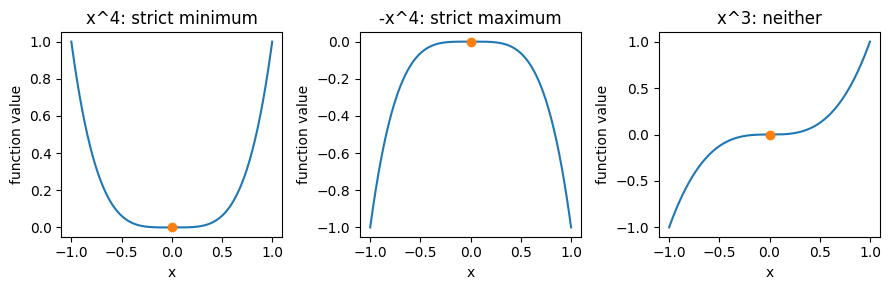

In [3]:
near_zero = np.array([-0.1, 0.0, 0.1])
print("x:", near_zero)
print("x^4:", near_zero**4)
print("-x^4:", -near_zero**4)
print("x^3:", near_zero**3)

grid = np.linspace(-1, 1, 301)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for axis, values, title in zip(axes, [grid**4, -grid**4, grid**3],
                              ["x^4: strict minimum", "-x^4: strict maximum", "x^3: neither"]):
    axis.plot(grid, values)
    axis.scatter([0], [0], color="tab:orange", zorder=3)
    axis.set(xlabel="x", ylabel="function value", title=title)
plt.tight_layout()
plt.show()

## 3.3.2. convexity and global minimizers

On a convex domain, a function is convex if

$$f((1-t)\mathbf{x}+t\mathbf{y})\le(1-t)f(\mathbf{x})+tf(\mathbf{y}),\qquad 0\le t\le1.$$

The function lies below the straight chord between two points on its graph. For a differentiable convex function, the tangent-plane inequality is

$$f(\mathbf{y})\ge f(\mathbf{x})+\nabla f(\mathbf{x})^T(\mathbf{y}-\mathbf{x}).$$

If the gradient at $\mathbf{x}$ is zero, this inequality makes $\mathbf{x}$ a global minimizer. Every local minimizer of a convex function is global. Strict convexity gives at most one minimizer, but does not by itself guarantee that a minimizer exists.

For a twice continuously differentiable function on an open convex domain, a positive semidefinite Hessian everywhere is equivalent to convexity. Checking the Hessian at only one point is not enough.

Our main example is

$$q(x,y)=(x-1)^2+4(y+2)^2,\qquad
\nabla q=\begin{bmatrix}2(x-1)\\8(y+2)\end{bmatrix},\qquad
H_q=\begin{bmatrix}2&0\\0&8\end{bmatrix}.$$

The Hessian is positive definite everywhere. The function is strongly convex, and its unique global minimizer is $(1,-2)$ with value zero. We can also see this directly because both squared terms are nonnegative and vanish together only there.

Hessian eigenvalues: [2. 8.]
minimizer: [ 1. -2.]
gradient there: [0. 0.]
minimum value: 0.0000
largest function-minus-chord value: 0.000000


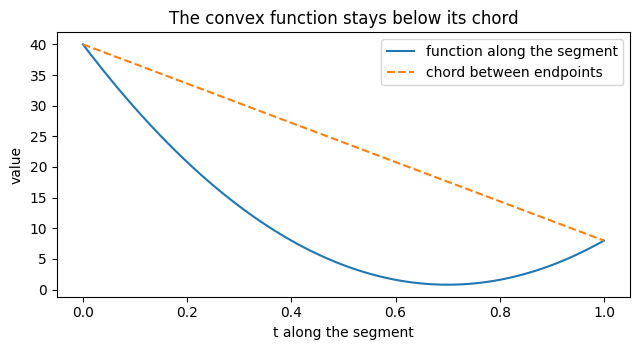

In [4]:
def objective(point):
    x, y = point
    return (x - 1)**2 + 4*(y + 2)**2

def gradient(point):
    x, y = point
    return np.array([2*(x - 1), 8*(y + 2)])

minimum = np.array([1.0, -2.0])
q_hessian = np.diag([2.0, 8.0])
point_a = np.array([-1.0, 1.0])
point_b = np.array([3.0, -3.0])
weights = np.linspace(0, 1, 101)
segment_values = np.array([objective((1-t)*point_a + t*point_b) for t in weights])
chord_values = (1-weights)*objective(point_a) + weights*objective(point_b)
print("Hessian eigenvalues:", np.linalg.eigvalsh(q_hessian))
print("minimizer:", minimum)
print("gradient there:", gradient(minimum))
print(f"minimum value: {objective(minimum):.4f}")
print(f"largest function-minus-chord value: {np.max(segment_values - chord_values):.6f}")

plt.figure(figsize=(6.5, 3.6))
plt.plot(weights, segment_values, label="function along the segment")
plt.plot(weights, chord_values, "--", label="chord between endpoints")
plt.xlabel("t along the segment")
plt.ylabel("value")
plt.title("The convex function stays below its chord")
plt.legend()
plt.tight_layout()
plt.show()

The sampled chord inequality holds, with equality at the endpoints. The plot illustrates convexity; the constant positive definite Hessian establishes it over the whole plane.

### a local minimum that is not global

For contrast, consider $h(x)=x^4-2x^2+0.4x$. Its derivatives are $h'(x)=4x^3-4x+0.4$ and $h''(x)=12x^2-4$. The negative curvature near zero means this function is not convex. We can solve for all three stationary points and compare their values.

x           function value    second derivative    type
-1.046681   -1.409544          9.146482       local minimum
 0.101031    0.020102         -3.877512       local maximum
 0.945649   -0.610558          6.731031       local minimum


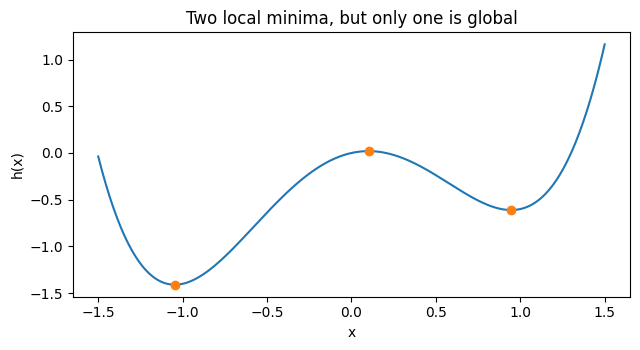

In [5]:
def tilted_well(x):
    return x**4 - 2*x**2 + 0.4*x

stationary_points = np.sort(np.roots([4.0, 0.0, -4.0, 0.4]).real)
well_values = tilted_well(stationary_points)
well_curvature = 12*stationary_points**2 - 4
print("x           function value    second derivative    type")
for x, value, curvature in zip(stationary_points, well_values, well_curvature):
    kind = "local minimum" if curvature > 0 else "local maximum"
    print(f"{x: .6f}   {value: .6f}         {curvature: .6f}       {kind}")

grid = np.linspace(-1.5, 1.5, 400)
plt.figure(figsize=(6.5, 3.6))
plt.plot(grid, tilted_well(grid))
plt.scatter(stationary_points, well_values, color="tab:orange", zorder=3)
plt.xlabel("x")
plt.ylabel("h(x)")
plt.title("Two local minima, but only one is global")
plt.tight_layout()
plt.show()

The left minimum is lower than the right one. Both pass the positive-second-derivative test, so both are strict local minima, but the right one is not global. Since $h(x)$ goes to infinity as $|x|$ grows and we found every stationary point, comparing the two minima identifies the global one. A plot alone would not justify that conclusion over all real numbers.

## 3.3.3. gradient descent

Gradient descent repeatedly moves opposite the gradient:

$$\mathbf{x}_{k+1}=\mathbf{x}_k-\alpha\nabla f(\mathbf{x}_k).$$

The step size $\alpha$ controls how far we move. The directional derivative along $-\nabla f$ is $-\|\nabla f\|^2$, so it is a descent direction when the gradient is nonzero. That does not mean every finite step will decrease the function.

For our quadratic, the gradient is Lipschitz with constant $L=8$, the largest Hessian eigenvalue. The descent bound

$$f(\mathbf{x}-\alpha\nabla f(\mathbf{x}))\le f(\mathbf{x})
-\alpha(1-L\alpha/2)\|\nabla f(\mathbf{x})\|^2$$

guarantees a decrease away from the minimum when $0<\alpha<2/L=0.25$. The usual conservative choice $\alpha\le1/L$ is inside this range. Here we use $\alpha=0.1$ and stop when the gradient norm is small, with an iteration cap so the loop cannot run forever.

In [6]:
def gradient_descent(start, learning_rate, max_steps=200, tolerance=1e-8):
    point = np.array(start, dtype=float)
    path = [point.copy()]
    for _ in range(max_steps):
        grad = gradient(point)
        if np.linalg.norm(grad) < tolerance:
            break
        point = point - learning_rate * grad
        path.append(point.copy())
    return np.array(path)

start = np.array([4.0, 1.0])
path = gradient_descent(start, 0.1)
losses = np.array([objective(point) for point in path])
print("starting point:", start)
print(f"starting value: {losses[0]:.6f}")
print(f"updates taken: {len(path) - 1}")
print("final point:", path[-1])
print(f"final function value: {losses[-1]:.3e}")
print(f"final gradient norm: {np.linalg.norm(gradient(path[-1])):.3e}")

starting point: [4. 1.]
starting value: 45.000000
updates taken: 91
final point: [ 1. -2.]
final function value: 2.073e-17
final gradient norm: 9.106e-09


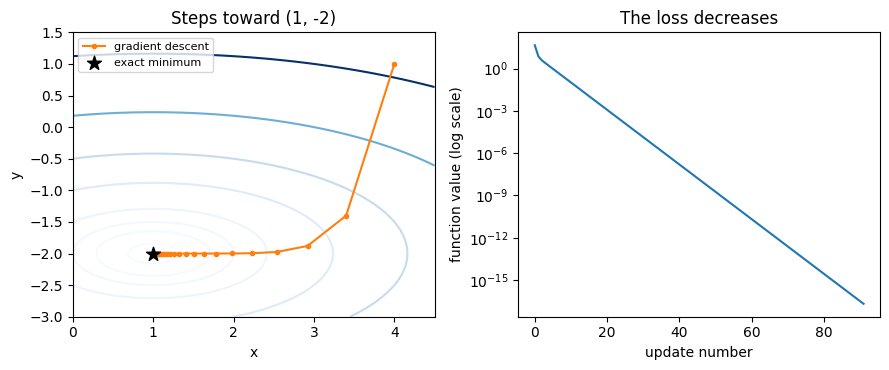

In [7]:
x_grid, y_grid = np.meshgrid(np.linspace(0, 4.5, 150), np.linspace(-3, 1.5, 150))
z_grid = (x_grid - 1)**2 + 4*(y_grid + 2)**2
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
axes[0].contour(x_grid, y_grid, z_grid, levels=[0.1, 0.5, 1, 2, 5, 10, 20, 40], cmap="Blues")
axes[0].plot(path[:, 0], path[:, 1], "o-", markersize=3, color="tab:orange", label="gradient descent")
axes[0].scatter(*minimum, marker="*", s=110, color="black", label="exact minimum", zorder=4)
axes[0].set(xlabel="x", ylabel="y", title="Steps toward (1, -2)")
axes[0].legend(fontsize=8)
axes[1].semilogy(np.arange(len(losses)), losses)
axes[1].set(xlabel="update number", ylabel="function value (log scale)", title="The loss decreases")
plt.tight_layout()
plt.show()

The iterates approach $(1,-2)$ and the gradient norm reaches the stopping tolerance. The final function value is close to zero, not necessarily exactly zero in floating-point arithmetic. The contours are steeper in the y-direction, which explains why that coordinate changes more quickly at first.

### what happens when the step is too large?

The coordinate errors satisfy

$$x_{k+1}-1=(1-2\alpha)(x_k-1),\qquad
y_{k+1}+2=(1-8\alpha)(y_k+2).$$

At $\alpha=0.1$, the factors are $0.8$ and $0.2$, so both errors shrink. At $0.24$, the second factor is $-0.92$, so that coordinate oscillates but still converges. At $0.3$, it is $-1.4$, so the error grows for our nonzero initial y-error. At the boundary $0.25$, the y-error would oscillate without shrinking. These statements follow from this particular quadratic; they are not a universal step-size rule for every objective.

rate 0.10: value after 40 updates = 1.590162e-07
rate 0.24: value after 40 updates = 4.563822e-02
rate 0.30: value after 40 updates = 1.764190e+13


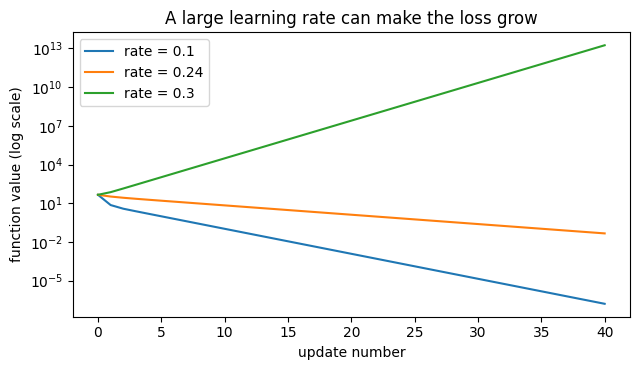

In [8]:
learning_rates = [0.1, 0.24, 0.3]
rate_paths = {}
rate_losses = {}
plt.figure(figsize=(6.5, 3.8))
for rate in learning_rates:
    trial = gradient_descent(start, rate, max_steps=40, tolerance=0)
    trial_losses = np.array([objective(point) for point in trial])
    rate_paths[rate] = trial
    rate_losses[rate] = trial_losses
    print(f"rate {rate:.2f}: value after 40 updates = {trial_losses[-1]:.6e}")
    plt.semilogy(np.arange(len(trial_losses)), trial_losses, label=f"rate = {rate}")
plt.xlabel("update number")
plt.ylabel("function value (log scale)")
plt.title("A large learning rate can make the loss grow")
plt.legend()
plt.tight_layout()
plt.show()

The $0.1$ run decreases quickly, the $0.24$ run decreases more slowly, and the $0.3$ run grows. A larger learning rate does not automatically mean faster progress. Also, a small gradient alone is not proof of a minimum for a nonconvex function: gradient descent can stop at a saddle if it starts exactly there. Our global conclusion for the main example depends on convexity, not just the stopping condition.

## quick checks

These checks compare the code with the formulas and expected behavior. They support the examples; the mathematical assumptions above are still needed for the general claims.

In [9]:
checks = {
    "minimum Hessian is positive definite": np.all(np.linalg.eigvalsh(hessians["x^2 + y^2"]) > 0),
    "saddle Hessian has both signs": np.linalg.det(hessians["x^2 - y^2"]) < 0,
    "quadratic minimizer is stationary": np.allclose(gradient(minimum), 0),
    "quadratic minimum value is zero": np.isclose(objective(minimum), 0),
    "sampled chord inequality holds": np.all(segment_values <= chord_values + 1e-12),
    "well stationary points solve the derivative": np.allclose(4*stationary_points**3 - 4*stationary_points + 0.4, 0),
    "well has two minima and a maximum": np.array_equal(well_curvature > 0, [True, False, True]),
    "left well is lower than the right well": well_values[0] < well_values[2],
    "gradient descent reaches the minimizer": np.allclose(path[-1], minimum, atol=1e-7),
    "gradient stopping tolerance is met": np.linalg.norm(gradient(path[-1])) < 1e-8,
    "stable run never increases the loss": np.all(np.diff(losses) <= 1e-12),
    "large step increases the final loss": rate_losses[0.3][-1] > rate_losses[0.3][0],
    "first update matches the error formula": np.allclose(path[1] - minimum, np.array([0.8, 0.2])*(start - minimum)),
}
for label, passed in checks.items():
    print(f"{label}: {bool(passed)}")
assert all(checks.values()), "one of the checks needs another look"

minimum Hessian is positive definite: True
saddle Hessian has both signs: True
quadratic minimizer is stationary: True
quadratic minimum value is zero: True
sampled chord inequality holds: True
well stationary points solve the derivative: True
well has two minima and a maximum: True
left well is lower than the right well: True
gradient descent reaches the minimizer: True
gradient stopping tolerance is met: True
stable run never increases the loss: True
large step increases the final loss: True
first update matches the error formula: True


## what I took from this

Stationary points need to be checked, not just found. The Hessian can distinguish a minimum from a saddle, but a zero eigenvalue can leave the answer undecided. Convexity is what makes a local minimum global in the main example. Gradient descent then gives us a practical way to approach it, as long as the step size fits the curvature of the function.

- AI use note: I had help from Codex in refining the code (not completely writing it), refining the latex of the report, and pushing it to GitHub. Other than that, the intial psuedocode/boilerplates, logic, and the report is still drafted by me. I ran every cell and reviewed the math and explanations before submitting.